In [43]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

#### Data loading

In [44]:
df = pd.read_csv("course_lead_scoring_2026.csv")

df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


#### Data preparation

In [45]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [46]:
# filling missing values
categorical_columns = ['lead_source', 'industry', 'employment_status', 'location']
numerical_columns = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical_columns] = df[categorical_columns].fillna('NA')
df[numerical_columns] = df[numerical_columns].fillna(0.0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [47]:
# splitting the data into 3 parts
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print('Full train:', len(df_full_train))
print('Train:', len(df_train))
print('Validation:', len(df_val))
print('Test:', len(df_test))

Full train: 4000
Train: 3000
Validation: 1000
Test: 1000


In [48]:
# converting variable targets to 0 or 1 for classification task
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_full_train = df_full_train['converted'].values

# removing converted column from the tables
df_train = df_train.drop(columns=['converted'])
df_val = df_val.drop(columns=['converted'])
df_full_train = df_full_train.drop(columns=['converted'])

print(list(df_train.columns))

['lead_source', 'industry', 'employment_status', 'location', 'annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']


#### ROC AUC feature importance

In [49]:
for col in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    print(col, '=', round(auc, 3))

lead_score = 0.788
number_of_courses_viewed = 0.723
interaction_count = 0.765
annual_income = 0.608


In [50]:
# finding the highes AUC score among the features
best_col = None
best_auc = 0

for col in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    if auc > best_auc:
        best_col = col
        best_auc = auc

print('highest AUC score', best_col)
print('with AUC =', round(best_auc, 3))

highest AUC score lead_score
with AUC = 0.788


#### model training

In [51]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

print('training matrix shape:', X_train.shape)
print('first few feature names:', list(dv.get_feature_names_out())[:10])


training matrix shape: (3000, 28)
first few feature names: ['annual_income', 'employment_status=NA', 'employment_status=employed', 'employment_status=self_employed', 'employment_status=student', 'employment_status=unemployed', 'industry=NA', 'industry=education', 'industry=finance', 'industry=healthcare']


In [52]:
# training the logistic regression model
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:,1]

val_auc = roc_auc_score(y_val, y_pred)
print('Validation AUC:', round(val_auc, 3))

Validation AUC: 0.732


#### computing precision and recall

In [53]:
# setting thereshold for classification
thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []
f1_scores = []

for t in thresholds:
    predict = (y_pred >= t)
    actual = (y_val == 1)

    tp = (predict & actual).sum()
    fp = (predict & ~actual).sum()
    fn = (~predict & actual).sum()

    if tp + fp > 0:
        p = tp / (tp+fp)
    else:
        p = 0.0
        
    if tp + fn > 0:
        r = tp / (tp+fn)
    else:
        r = 0.0
    
    if p + r > 0:
        f1 = 2 * p * r / (p + r)
    else:
        f1 = 0.0

    precisions.append(p)
    recalls.append(r)
    f1_scores.append(f1)

scores = pd.DataFrame({
    'threshold': thresholds,
    'precision': precisions,
    'recall': recalls,
    'f1_score': f1_scores
})
scores.iloc[::10]

,threshold,precision,recall,f1_score
0,0.0,0.586000,1.000000,0.738966
10,0.1,0.586000,1.000000,0.738966
20,0.2,0.586000,1.000000,0.738966
30,0.3,0.592518,1.000000,0.744127
40,0.4,0.612834,0.977816,0.753452
50,0.5,0.643636,0.906143,0.752658
60,0.6,0.706337,0.779863,0.741281
70,0.7,0.791349,0.530717,0.635342
80,0.8,0.858025,0.237201,0.371658
90,0.9,0.950000,0.032423,0.062706


#### Plotting precision and recall

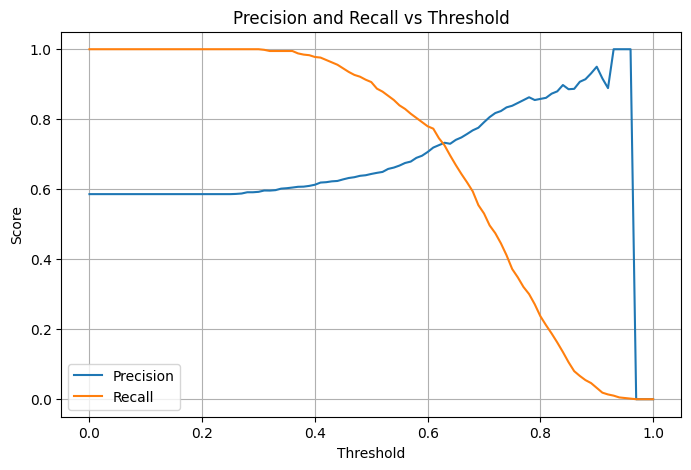

In [54]:
plt.figure(figsize=(8, 5))
plt.plot(scores['threshold'], scores['precision'], label='Precision')
plt.plot(scores['threshold'], scores['recall'], label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(True)
plt.show()

In [55]:
### finding the exact number of curves where they're intersecting
valid = scores[(scores['precision'] > 0) | (scores['recall'] > 0)].copy()

valid['diff'] = (valid['precision'] - valid['recall']).abs()

best_row = valid.loc[valid['diff'].idxmin()]
print('Intersection threshold:', round(best_row['threshold'], 2))
print('Precision :', round(best_row['precision'], 3), '| Recall:', round(best_row['recall'], 3))

Intersection threshold: 0.63
Precision : 0.733 | Recall: 0.725


#### Computing f1 score

the formula given were $$F_1 = 2 \cdot \frac{P \cdot R}{P + R}$$

In [58]:
best_f1_row = scores.loc[scores['f1_score'].idxmax()]
print('threshold with max f1:', round(best_f1_row['threshold'], 2))
print('f1 :', round(best_f1_row['f1_score'], 3))

threshold with max f1: 0.41
f1 : 0.758


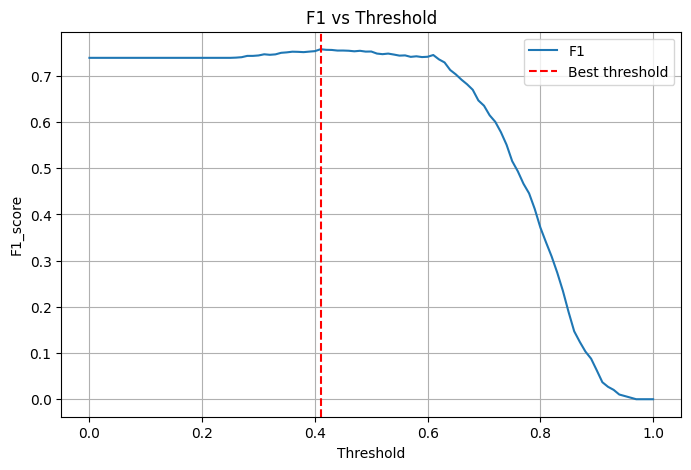

In [60]:
# plotting f1 score vs threshold
plt.figure(figsize=(8, 5))
plt.plot(scores['threshold'], scores['f1_score'], label='F1')
plt.axvline(best_f1_row['threshold'], color='red', linestyle='--', label='Best threshold')
plt.xlabel('Threshold')
plt.ylabel('F1_score')
plt.title('F1 vs Threshold')
plt.legend()
plt.grid(True)
plt.show()